Cài đặt thư viện


In [26]:
!pip install pandas==2.2.3

In [27]:
import pandas as pd

print(pd.__version__)

2.2.3


In [28]:

!pip -q install -U sentence-transformers datasets faiss-cpu scikit-learn matplotlib tqdm
!pip -q install pandas==2.2.3

In [29]:

import os, re, json, time, math, random, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from sentence_transformers import SentenceTransformer
from datasets import load_dataset
from sklearn.cluster import MiniBatchKMeans
import faiss
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("FAISS:", faiss.__version__)
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/ANN_Vector_Embedding')
DATA_DIR = PROJECT_DIR / 'data'
RESULT_DIR = PROJECT_DIR / 'results'
MODEL_DIR = PROJECT_DIR / 'models'
for p in [PROJECT_DIR, DATA_DIR, RESULT_DIR, MODEL_DIR]:
    p.mkdir(parents=True, exist_ok=True)
N_CORPUS = 20000
N_QUERIES = 500
TOP_K = 10
MODEL_NAME = 'intfloat/multilingual-e5-small'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Thư mục dự án:", PROJECT_DIR)
print("Cấu hình:", N_CORPUS, "câu corpus;", N_QUERIES, "truy vấn")

Python: 3.13.18
PyTorch: 2.14.1+cpu
CUDA available: False
FAISS: 1.16.0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục dự án: /content/drive/MyDrive/ANN_Vector_Embedding
Cấu hình: 20000 câu corpus; 500 truy vấn


Thu thập và làm sạch dữ liệu tiếng Việt

In [30]:
dataset = load_dataset('wikimedia/wikipedia', '20231101.vi', split='train', streaming=True)

def split_vietnamese_sentences(text):
    text = re.sub(r'\s+', ' ', str(text)).strip()
    parts = re.split(r'(?<=[.!?。])\s+', text)
    out = []
    for s in parts:
        s = s.strip(' \\t\\n-•')
        words = s.split()
        if 8 <= len(words) <= 60 and len(s) >= 40:
            out.append(s)
    return out

sentences = []
seen = set()
for row in tqdm(dataset, desc='Đọc Wikipedia'):
    article = row.get('text', '')
    for sent in split_vietnamese_sentences(article):
        key = sent.lower()
        if key not in seen:
            seen.add(key)
            sentences.append(sent)
        if len(sentences) >= N_CORPUS + N_QUERIES:
            break
    if len(sentences) >= N_CORPUS + N_QUERIES:
        break

if len(sentences) < N_CORPUS + N_QUERIES:
    raise RuntimeError(
        f'Chỉ thu được {len(sentences)} câu, cần {N_CORPUS + N_QUERIES}. '
        'Hãy chạy lại cell hoặc đổi nguồn/tăng thời gian tải.'
    )
rng = np.random.default_rng(SEED)
order = rng.permutation(len(sentences))
sentences = [sentences[i] for i in order]

corpus_texts = sentences[:N_CORPUS]
query_texts = sentences[N_CORPUS:N_CORPUS + N_QUERIES]

with open(DATA_DIR/'corpus_vi.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(corpus_texts))
with open(DATA_DIR/'queries_vi.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(query_texts))

print("Số câu corpus:", len(corpus_texts))
print("Số câu query:", len(query_texts))
print("\nVí dụ corpus:", corpus_texts[0])
print("\nVí dụ query:", query_texts[0])

Đọc Wikipedia: 0it [00:00, ?it/s]

Số câu corpus: 20000
Số câu query: 500

Ví dụ corpus: Campuchia phải đối mặt với hai nước láng giềng ngày càng hùng mạnh, Ayutthaya của Thái Lan và triều Nguyễn của Việt Nam, và đánh dấu sự đi xuống của số phận Campuchia.

Ví dụ query: 1841) 1785 - Vua Louis XVII của Pháp (m.


Tạo embedding bằng multilingual-e5-small

In [32]:
model = SentenceTransformer(MODEL_NAME, device=DEVICE)

corpus_inputs = ['passage: ' + x for x in corpus_texts]
query_inputs = ['query: ' + x for x in query_texts]

t0 = time.perf_counter()
corpus_embeddings = model.encode(
    corpus_inputs, batch_size=128, show_progress_bar=True,
    convert_to_numpy=True, normalize_embeddings=True
).astype('float32')
embedding_corpus_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
query_embeddings = model.encode(
    query_inputs, batch_size=128, show_progress_bar=True,
    convert_to_numpy=True, normalize_embeddings=True
).astype('float32')
embedding_query_seconds = time.perf_counter() - t0

np.save(DATA_DIR/'corpus_embeddings.npy', corpus_embeddings)
np.save(DATA_DIR/'query_embeddings.npy', query_embeddings)

print("Corpus shape:", corpus_embeddings.shape)
print("Query shape:", query_embeddings.shape)
print("Thời gian embedding corpus (s):", round(embedding_corpus_seconds, 2))
print("Thời gian embedding query (s):", round(embedding_query_seconds, 2))
print("Norm vector đầu tiên:", np.linalg.norm(corpus_embeddings[0]))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Corpus shape: (20000, 384)
Query shape: (500, 384)
Thời gian embedding corpus (s): 1205.6
Thời gian embedding query (s): 32.72
Norm vector đầu tiên: 1.0


Brute Force và Ground Truth

In [33]:
def exact_search(query_vecs, database_vecs, k=10, batch_size=32):
    db_t = torch.from_numpy(database_vecs)
    if torch.cuda.is_available():
        db_t = db_t.to('cuda')
    all_ids = []
    all_scores = []
    for start in range(0, len(query_vecs), batch_size):
        q_t = torch.from_numpy(query_vecs[start:start+batch_size])
        if torch.cuda.is_available():
            q_t = q_t.to('cuda')
        scores = q_t @ db_t.T
        vals, ids = torch.topk(scores, k=k, dim=1, largest=True, sorted=True)
        all_ids.append(ids.cpu().numpy())
        all_scores.append(vals.cpu().numpy())
    return np.vstack(all_ids), np.vstack(all_scores)

t0 = time.perf_counter()
ground_truth_ids, ground_truth_scores = exact_search(
    query_embeddings, corpus_embeddings, k=TOP_K, batch_size=16
)
exact_total_seconds = time.perf_counter() - t0
exact_ms_per_query = exact_total_seconds / len(query_embeddings) * 1000

np.save(RESULT_DIR/'ground_truth_top10.npy', ground_truth_ids)
np.save(RESULT_DIR/'ground_truth_scores.npy', ground_truth_scores)
print("Ground Truth:", ground_truth_ids.shape)
print("Brute Force tổng (s):", round(exact_total_seconds, 3))
print("Brute Force trung bình (ms/query):", round(exact_ms_per_query, 3))

Ground Truth: (500, 10)
Brute Force tổng (s): 0.579
Brute Force trung bình (ms/query): 1.158


In [34]:
#  HÀM ĐÁNH GIÁ CHUNG
def recall_at_k(result_ids, truth_ids, k=10):
    values = []
    for pred, truth in zip(result_ids, truth_ids):
        values.append(len(set(map(int, pred[:k])) & set(map(int, truth[:k]))) / k)
    return float(np.mean(values))

def evaluate_method(name, search_fn, queries=query_embeddings, truth=ground_truth_ids, k=10):
    # Đo nhiều lượt để giảm nhiễu do hệ thống; báo cáo trung vị.
    runs = []
    result = None
    for _ in range(3):
        t0 = time.perf_counter()
        result = search_fn(queries, k)
        runs.append((time.perf_counter() - t0) * 1000 / len(queries))
    latency = float(np.median(runs))
    rec = recall_at_k(result, truth, k)
    return {'method': name, 'recall@10': rec, 'ms_per_query': latency,
            'queries_per_second': 1000/latency if latency > 0 else np.nan}, result

# Kiểm tra Brute Force phải đạt Recall@10 = 1.0 so với chính Ground Truth.
bf_row, bf_ids = evaluate_method(
    'Brute Force',
    lambda q, k: exact_search(q, corpus_embeddings, k=k, batch_size=16)[0]
)
print(bf_row)

{'method': 'Brute Force', 'recall@10': 1.0, 'ms_per_query': 0.7963235119987075, 'queries_per_second': 1255.7710339232367}


Tự cài đặt LSH siêu phẳng ngẫu nhiên

In [35]:
#  LSH RANDOM HYPERPLANES
class RandomHyperplaneLSH:
    def __init__(self, n_bits=12, n_tables=4, seed=42):
        self.n_bits = n_bits
        self.n_tables = n_tables
        self.seed = seed
        self.planes = []
        self.tables = []
        self.codes = []

    def _hash_codes(self, X, planes):
        # planes shape is expected to be (n_bits, d)
        signs = (X @ planes.T) >= 0
        # Mã số nguyên từ chuỗi bit; n_bits mặc định <= bit_length an toàn.
        weights = (1 << np.arange(self.n_bits, dtype=np.uint64))
        return (signs.astype(np.uint64) * weights).sum(axis=1)

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        self.planes, self.tables, self.codes = [], [], []
        d = X.shape[1]
        for _ in range(self.n_tables):
            # Sửa đổi ở đây: tạo ma trận planes có kích thước (n_bits, d)
            planes = rng.normal(size=(self.n_bits, d)).astype('float32')
            codes = self._hash_codes(X, planes)
            table = {}
            for idx, code_value in enumerate(codes):
                table.setdefault(int(code_value), []).append(idx)
            self.planes.append(planes)
            self.tables.append(table)
            self.codes.append(codes)
        return self

    def _candidate_ids(self, q, min_candidates=100):
        candidates = set()
        for planes, table, codes in zip(self.planes, self.tables, self.codes):
            code = int(self._hash_codes(q[None, :], planes)[0])
            candidates.update(table.get(code, []))
            # Mở rộng Hamming: lật từng bit cho đến khi đủ ứng viên.
            if len(candidates) < min_candidates:
                for bit in range(self.n_bits):
                    neighbor_code = code ^ (1 << bit)
                    candidates.update(table.get(neighbor_code, []))
                    if len(candidates) >= min_candidates:
                        break
        return np.fromiter(candidates, dtype=np.int64) if candidates else np.array([], dtype=np.int64)

    def search_one(self, q, k=10, min_candidates=100):
        cand = self._candidate_ids(q, min_candidates)
        if len(cand) == 0:
            # Fallback an toàn; trường hợp này không còn là truy vấn ANN thuần.
            cand = np.arange(len(corpus_embeddings))
        scores = corpus_embeddings[cand] @ q
        take = min(k, len(cand))
        return cand[np.argpartition(-scores, take-1)[:take]][np.argsort(-scores[np.argpartition(-scores, take-1)[:take]])]

    def search(self, Q, k=10, min_candidates=100):
        out = []
        for q in Q:
            out.append(self.search_one(q, k, min_candidates))
        return np.asarray(out, dtype=np.int64)

# Chạy thí nghiệm nhiều cấu hình bit và bảng.
lsh_rows = []
lsh_objects = {}
for bits in [8, 12, 16]:
    for tables in [2, 4, 8]:
        lsh = RandomHyperplaneLSH(n_bits=bits, n_tables=tables, seed=SEED).fit(corpus_embeddings)
        fn = lambda Q, k, obj=lsh: obj.search(Q, k=k, min_candidates=100)
        row, ids = evaluate_method(f'LSH bits={bits}, tables={tables}', fn)
        row.update({'n_bits': bits, 'n_tables': tables})
        lsh_rows.append(row)
        lsh_objects[(bits, tables)] = lsh
        np.save(RESULT_DIR/f'lsh_b{bits}_t{tables}_top10.npy', ids)

lsh_df = pd.DataFrame(lsh_rows).sort_values(['n_bits','n_tables'])
display(lsh_df)

,method,recall@10,ms_per_query,queries_per_second,n_bits,n_tables
0,"LSH bits=8, tables=2",0.3060,2.705384,369.633344,8,2
1,"LSH bits=8, tables=4",0.5994,6.899278,144.942706,8,4
2,"LSH bits=8, tables=8",0.8020,16.514395,60.553231,8,8
3,"LSH bits=12, tables=2",0.1602,1.158029,863.536538,12,2
4,"LSH bits=12, tables=4",0.2852,2.176046,459.549173,12,4
5,"LSH bits=12, tables=8",0.5478,7.466631,133.929218,12,8
6,"LSH bits=16, tables=2",0.1006,0.676362,1478.497173,16,2
7,"LSH bits=16, tables=4",0.1486,0.948064,1054.780558,16,4
8,"LSH bits=16, tables=8",0.2984,2.193766,455.837063,16,8


Cìa đặt thêm IVF (Inverted File Index)

In [36]:
# 7A. IVF TỰ CÀI
class SimpleIVF:
    def __init__(self, nlist=100, random_state=42):
        self.nlist = nlist
        self.kmeans = None
        self.inverted_lists = None
        self.X = None

    def fit(self, X):
        self.X = X
        self.kmeans = MiniBatchKMeans(
            n_clusters=self.nlist, random_state=SEED,
            batch_size=2048, n_init=3, max_iter=100
        )
        labels = self.kmeans.fit_predict(X)
        self.inverted_lists = [np.where(labels == i)[0] for i in range(self.nlist)]
        return self

    def search(self, Q, k=10, nprobe=5):
        centers = self.kmeans.cluster_centers_.astype('float32')
        out = []
        for q in Q:
            center_scores = centers @ q
            probes = np.argpartition(-center_scores, nprobe-1)[:nprobe]
            cand = np.concatenate([self.inverted_lists[i] for i in probes])
            if len(cand) == 0:
                out.append(np.zeros(k, dtype=np.int64))
                continue
            scores = self.X[cand] @ q
            take = min(k, len(cand))
            local = np.argpartition(-scores, take-1)[:take]
            local = local[np.argsort(-scores[local])]
            chosen = cand[local]
            if len(chosen) < k:
                # Bổ sung nếu cụm quá nhỏ.
                chosen = np.pad(chosen, (0, k-len(chosen)), constant_values=chosen[-1])
            out.append(chosen[:k])
        return np.asarray(out, dtype=np.int64)

ivf_rows = []
ivf_models = {}
for nlist in [50, 100, 200]:
    ivf = SimpleIVF(nlist=nlist).fit(corpus_embeddings)
    ivf_models[nlist] = ivf
    for nprobe in [1, 5, 10, 20]:
        fn = lambda Q, k, obj=ivf, p=nprobe: obj.search(Q, k=k, nprobe=p)
        row, ids = evaluate_method(f'IVF nlist={nlist}, nprobe={nprobe}', fn)
        row.update({'nlist': nlist, 'nprobe': nprobe})
        ivf_rows.append(row)
        np.save(RESULT_DIR/f'ivf_l{nlist}_p{nprobe}_top10.npy', ids)

ivf_df = pd.DataFrame(ivf_rows).sort_values(['nlist','nprobe'])
display(ivf_df)

,method,recall@10,ms_per_query,queries_per_second,nlist,nprobe
0,"IVF nlist=50, nprobe=1",0.4676,0.252748,3956.507787,50,1
1,"IVF nlist=50, nprobe=5",0.8464,1.539970,649.363304,50,5
2,"IVF nlist=50, nprobe=10",0.9368,3.159569,316.498911,50,10
3,"IVF nlist=50, nprobe=20",0.9858,7.714948,129.618506,50,20
4,"IVF nlist=100, nprobe=1",0.4242,0.220133,4542.698820,100,1
5,"IVF nlist=100, nprobe=5",0.7848,2.437300,410.290118,100,5
6,"IVF nlist=100, nprobe=10",0.8888,1.529865,653.652367,100,10
7,"IVF nlist=100, nprobe=20",0.9532,3.146254,317.838336,100,20
8,"IVF nlist=200, nprobe=1",0.2610,0.100456,9954.641279,200,1
9,"IVF nlist=200, nprobe=5",0.6834,0.283152,3531.671935,200,5


Cài đặt NSW – đồ thị một tầng, tìm kiếm tham lam

In [37]:
# 8A. NSW TỰ CÀI
class SimpleNSW:
    def __init__(self, M=12, build_candidates=1200, seed=42):
        self.M = M
        self.build_candidates = build_candidates
        self.seed = seed
        self.X = None
        self.graph = None

    def fit(self, X):
        self.X = X
        n, d = X.shape
        rng = np.random.default_rng(self.seed)
        self.graph = [[] for _ in range(n)]
        # Để khả thi trên Colab, mỗi nút chỉ so sánh với một tập ứng viên ngẫu nhiên
        # thay vì tính toàn bộ ma trận N x N. Đây là cách dựng NSW xấp xỉ.
        # Thêm cạnh vòng (i-1, i+1) để tăng liên thông cơ bản.
        pool_size = min(self.build_candidates, n)
        for i in tqdm(range(n), desc=f'Build NSW M={self.M}'):
            pool = rng.choice(n, size=pool_size, replace=False)
            pool = pool[pool != i]
            if len(pool) == 0:
                continue
            sims = X[pool] @ X[i]
            take = min(self.M, len(pool))
            best = np.argpartition(-sims, take-1)[:take]
            nbrs = pool[best].tolist()
            if i > 0:
                nbrs.append(i-1)
            if i < n-1:
                nbrs.append(i+1)
            self.graph[i] = list(dict.fromkeys(nbrs))
        return self

    def search_one(self, q, k=10, max_steps=100):
        current = 0
        current_score = float(self.X[current] @ q)
        visited = {current}
        for _ in range(max_steps):
            neighbors = self.graph[current]
            if not neighbors:
                break
            scores = self.X[neighbors] @ q
            best_pos = int(np.argmax(scores))
            if float(scores[best_pos]) <= current_score:
                break
            current = int(neighbors[best_pos])
            current_score = float(scores[best_pos])
            visited.add(current)
        candidates = set(visited)
        candidates.update(self.graph[current])
        cand = np.fromiter(candidates, dtype=np.int64)
        scores = self.X[cand] @ q
        take = min(k, len(cand))
        loc = np.argpartition(-scores, take-1)[:take]
        loc = loc[np.argsort(-scores[loc])]
        result = cand[loc]
        if len(result) < k:
            result = np.pad(result, (0, k-len(result)), constant_values=0)
        return result[:k]

    def search(self, Q, k=10):
        return np.asarray([self.search_one(q, k) for q in Q], dtype=np.int64)

# Bản NSW tự cài dùng dựng đồ thị xấp xỉ để giảm chi phí trên Colab.
# Tăng build_candidates có thể cải thiện chất lượng đồ thị nhưng tốn thời gian hơn.
nsw_rows = []
nsw_models = {}
for M in [8, 12, 20]:
    nsw = SimpleNSW(M=M, build_candidates=1200, seed=SEED).fit(corpus_embeddings)
    nsw_models[M] = nsw
    row, ids = evaluate_method(f'NSW M={M}', lambda Q, k, obj=nsw: obj.search(Q, k))
    row.update({'M': M})
    nsw_rows.append(row)
    np.save(RESULT_DIR/f'nsw_M{M}_top10.npy', ids)

nsw_df = pd.DataFrame(nsw_rows)
display(nsw_df)

Build NSW M=8:   0%|          | 0/20000 [00:00<?, ?it/s]

Build NSW M=12:   0%|          | 0/20000 [00:00<?, ?it/s]

Build NSW M=20:   0%|          | 0/20000 [00:00<?, ?it/s]

,method,recall@10,ms_per_query,queries_per_second,M
0,NSW M=8,0.0174,0.072638,13766.911377,8
1,NSW M=12,0.0294,0.116731,8566.720204,12
2,NSW M=20,0.0460,0.111227,8990.662711,20


Đối chiếu với FAISS

In [38]:
# 9A. FAISS FLAT (CHÍNH XÁC)
d = corpus_embeddings.shape[1]
index_flat = faiss.IndexFlatIP(d)
index_flat.add(corpus_embeddings)
t0 = time.perf_counter()
flat_scores, flat_ids = index_flat.search(query_embeddings, TOP_K)
faiss_flat_ms = (time.perf_counter()-t0)*1000/len(query_embeddings)
print("FAISS Flat Recall@10:", recall_at_k(flat_ids, ground_truth_ids, TOP_K))
print("FAISS Flat ms/query:", round(faiss_flat_ms, 3))

FAISS Flat Recall@10: 1.0
FAISS Flat ms/query: 0.559


In [39]:
# 9B. FAISS IVF
faiss_ivf_rows = []
nlist_faiss = 100
quantizer = faiss.IndexFlatIP(d)
index_ivf = faiss.IndexIVFFlat(quantizer, d, nlist_faiss, faiss.METRIC_INNER_PRODUCT)
index_ivf.train(corpus_embeddings)
index_ivf.add(corpus_embeddings)

for nprobe in [1, 5, 10, 20, 50]:
    index_ivf.nprobe = nprobe
    t0 = time.perf_counter()
    scores, ids = index_ivf.search(query_embeddings, TOP_K)
    latency = (time.perf_counter()-t0)*1000/len(query_embeddings)
    row = {'method': f'FAISS IVF nprobe={nprobe}',
           'recall@10': recall_at_k(ids, ground_truth_ids, TOP_K),
           'ms_per_query': latency, 'queries_per_second': 1000/latency,
           'nlist': nlist_faiss, 'nprobe': nprobe}
    faiss_ivf_rows.append(row)
    np.save(RESULT_DIR/f'faiss_ivf_p{nprobe}_top10.npy', ids)
faiss_ivf_df = pd.DataFrame(faiss_ivf_rows)
display(faiss_ivf_df)

,method,recall@10,ms_per_query,queries_per_second,nlist,nprobe
0,FAISS IVF nprobe=1,0.4602,0.044980,22231.918303,100,1
1,FAISS IVF nprobe=5,0.8088,0.159827,6256.781021,100,5
2,FAISS IVF nprobe=10,0.9130,0.310532,3220.283561,100,10
3,FAISS IVF nprobe=20,0.9660,0.557910,1792.403092,100,20
4,FAISS IVF nprobe=50,0.9960,1.497788,667.651404,100,50


In [40]:
# 9C. FAISS HNSW
faiss_hnsw_rows = []
for M in [16, 32]:
    index_hnsw = faiss.IndexHNSWFlat(d, M, faiss.METRIC_INNER_PRODUCT)
    index_hnsw.hnsw.efConstruction = 100
    index_hnsw.add(corpus_embeddings)
    for ef in [32, 64, 128, 256]:
        index_hnsw.hnsw.efSearch = ef
        t0 = time.perf_counter()
        scores, ids = index_hnsw.search(query_embeddings, TOP_K)
        latency = (time.perf_counter()-t0)*1000/len(query_embeddings)
        row = {'method': f'FAISS HNSW M={M}, efSearch={ef}',
               'recall@10': recall_at_k(ids, ground_truth_ids, TOP_K),
               'ms_per_query': latency, 'queries_per_second': 1000/latency,
               'M': M, 'efSearch': ef}
        faiss_hnsw_rows.append(row)
        np.save(RESULT_DIR/f'faiss_hnsw_M{M}_ef{ef}_top10.npy', ids)
faiss_hnsw_df = pd.DataFrame(faiss_hnsw_rows)
display(faiss_hnsw_df)

,method,recall@10,ms_per_query,queries_per_second,M,efSearch
0,"FAISS HNSW M=16, efSearch=32",0.9338,0.129419,7726.818517,16,32
1,"FAISS HNSW M=16, efSearch=64",0.9756,0.243185,4112.099348,16,64
2,"FAISS HNSW M=16, efSearch=128",0.9940,0.438937,2278.233566,16,128
3,"FAISS HNSW M=16, efSearch=256",0.9988,0.795702,1256.751678,16,256
4,"FAISS HNSW M=32, efSearch=32",0.9584,0.212973,4695.431273,32,32
5,"FAISS HNSW M=32, efSearch=64",0.9860,0.393025,2544.369245,32,64
6,"FAISS HNSW M=32, efSearch=128",0.9962,0.729833,1370.176315,32,128
7,"FAISS HNSW M=32, efSearch=256",0.9990,1.287810,776.512131,32,256


Tổng hợp kết quả và biểu đồ Recall – tốc độ

In [41]:
# 10A. GỘP BẢNG KẾT QUẢ
frames = [pd.DataFrame([bf_row]), lsh_df, ivf_df, nsw_df,
          faiss_ivf_df, faiss_hnsw_df]
all_results = pd.concat(frames, ignore_index=True, sort=False)
all_results.to_csv(RESULT_DIR/'comparison_results.csv', index=False, encoding='utf-8-sig')
display(all_results.sort_values('recall@10', ascending=False))

,method,recall@10,ms_per_query,queries_per_second,n_bits,n_tables,nlist,nprobe,M,efSearch
0,Brute Force,1.0000,0.796324,1255.771034,NaN,NaN,NaN,NaN,NaN,NaN
37,"FAISS HNSW M=32, efSearch=256",0.9990,1.287810,776.512131,NaN,NaN,NaN,NaN,32.0,256.0
33,"FAISS HNSW M=16, efSearch=256",0.9988,0.795702,1256.751678,NaN,NaN,NaN,NaN,16.0,256.0
36,"FAISS HNSW M=32, efSearch=128",0.9962,0.729833,1370.176315,NaN,NaN,NaN,NaN,32.0,128.0
29,FAISS IVF nprobe=50,0.9960,1.497788,667.651404,NaN,NaN,100.0,50.0,NaN,NaN
32,"FAISS HNSW M=16, efSearch=128",0.9940,0.438937,2278.233566,NaN,NaN,NaN,NaN,16.0,128.0
35,"FAISS HNSW M=32, efSearch=64",0.9860,0.393025,2544.369245,NaN,NaN,NaN,NaN,32.0,64.0
13,"IVF nlist=50, nprobe=20",0.9858,7.714948,129.618506,NaN,NaN,50.0,20.0,NaN,NaN
31,"FAISS HNSW M=16, efSearch=64",0.9756,0.243185,4112.099348,NaN,NaN,NaN,NaN,16.0,64.0
28,FAISS IVF nprobe=20,0.9660,0.557910,1792.403092,NaN,NaN,100.0,20.0,NaN,NaN


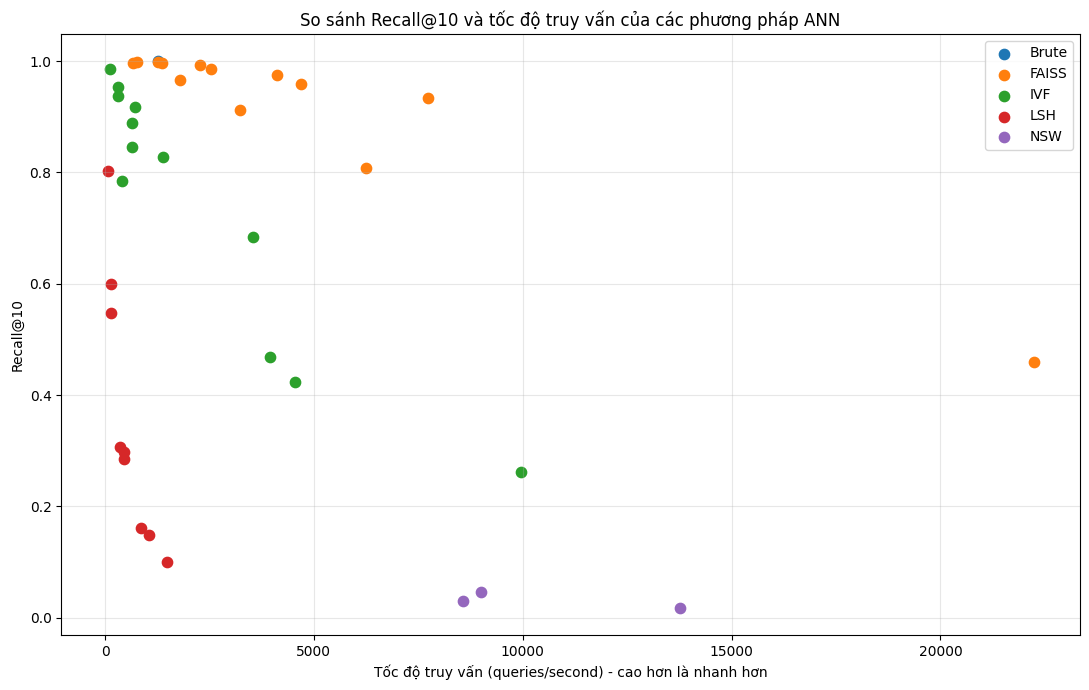

In [42]:
# 10B. BIỂU ĐỒ RECALL@10 THEO TỐC ĐỘ TRUY VẤN
plt.figure(figsize=(11, 7))
for method_group, group in all_results.groupby(
    all_results['method'].str.split().str[0]
):
    plt.scatter(group['queries_per_second'], group['recall@10'], label=method_group, s=55)
plt.xlabel('Tốc độ truy vấn (queries/second) - cao hơn là nhanh hơn')
plt.ylabel('Recall@10')
plt.title('So sánh Recall@10 và tốc độ truy vấn của các phương pháp ANN')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR/'recall_vs_qps.png', dpi=180)
plt.show()

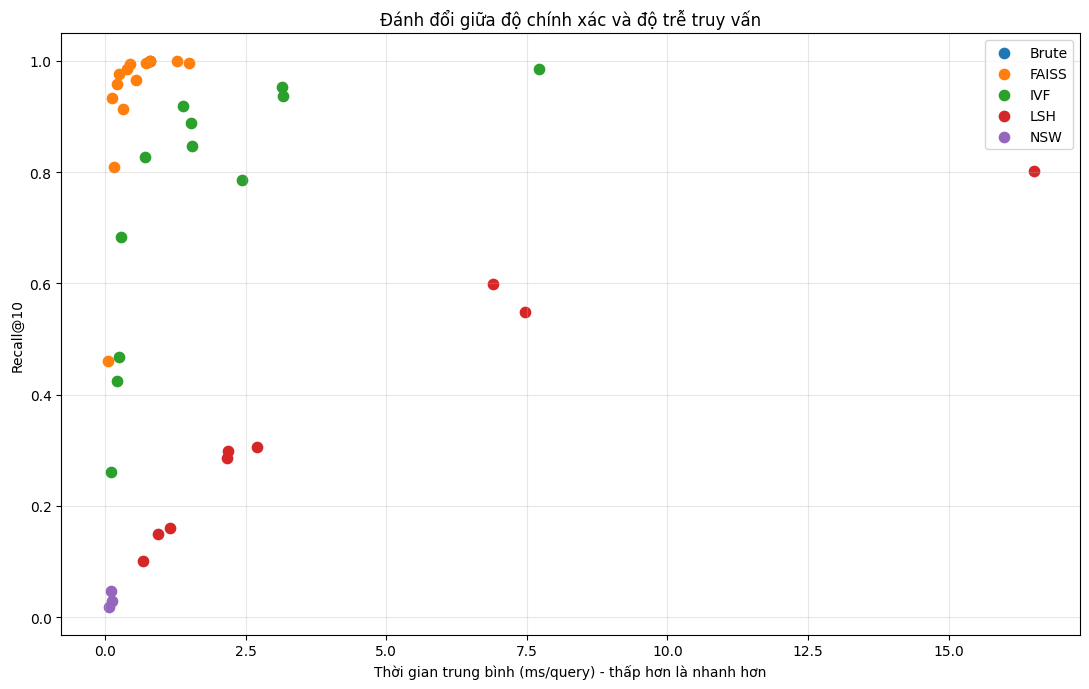

In [43]:
# 10C. BIỂU ĐỒ LATENCY VÀ RECALL
plt.figure(figsize=(11, 7))
for method_group, group in all_results.groupby(
    all_results['method'].str.split().str[0]
):
    plt.scatter(group['ms_per_query'], group['recall@10'], label=method_group, s=55)
plt.xlabel('Thời gian trung bình (ms/query) - thấp hơn là nhanh hơn')
plt.ylabel('Recall@10')
plt.title('Đánh đổi giữa độ chính xác và độ trễ truy vấn')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR/'recall_vs_latency.png', dpi=180)
plt.show()

Phân tích kết quả tự động và xuất bảng

In [44]:
# 11A. TÓM TẮT KẾT QUẢ THỰC NGHIỆM
valid = all_results.dropna(subset=['recall@10','queries_per_second']).copy()
best_recall = valid.loc[valid['recall@10'].idxmax()]
best_speed = valid.loc[valid['queries_per_second'].idxmax()]
print("Cấu hình Recall@10 cao nhất:")
display(best_recall.to_frame('value'))
print("\nCấu hình QPS cao nhất:")
display(best_speed.to_frame('value'))

summary = {
    'model': MODEL_NAME,
    'corpus_size': len(corpus_texts),
    'query_size': len(query_texts),
    'dimension': int(corpus_embeddings.shape[1]),
    'top_k': TOP_K,
    'device': DEVICE,
    'exact_bruteforce_ms_per_query': exact_ms_per_query,
    'best_recall_method': str(best_recall['method']),
    'best_recall_at_10': float(best_recall['recall@10']),
    'best_speed_method': str(best_speed['method']),
    'best_speed_qps': float(best_speed['queries_per_second'])
}
with open(RESULT_DIR/'experiment_summary.json','w',encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))

Cấu hình Recall@10 cao nhất:


,value
method,Brute Force
recall@10,1.0
ms_per_query,0.796324
queries_per_second,1255.771034
n_bits,NaN
n_tables,NaN
nlist,NaN
nprobe,NaN
M,NaN
efSearch,NaN



Cấu hình QPS cao nhất:


,value
method,FAISS IVF nprobe=1
recall@10,0.4602
ms_per_query,0.04498
queries_per_second,22231.918303
n_bits,NaN
n_tables,NaN
nlist,100.0
nprobe,1.0
M,NaN
efSearch,NaN


{
  "model": "intfloat/multilingual-e5-small",
  "corpus_size": 20000,
  "query_size": 500,
  "dimension": 384,
  "top_k": 10,
  "device": "cpu",
  "exact_bruteforce_ms_per_query": 1.157993651999277,
  "best_recall_method": "Brute Force",
  "best_recall_at_10": 1.0,
  "best_speed_method": "FAISS IVF nprobe=1",
  "best_speed_qps": 22231.918303178674
}


Kiểm tra tính đúng đắn và lưu

In [45]:
# 12A. VALIDATION
assert corpus_embeddings.shape[0] == N_CORPUS
assert query_embeddings.shape[0] == N_QUERIES
assert corpus_embeddings.shape[1] == query_embeddings.shape[1]
assert ground_truth_ids.shape == (N_QUERIES, TOP_K)
assert np.all(ground_truth_ids >= 0) and np.all(ground_truth_ids < N_CORPUS)
norms = np.linalg.norm(corpus_embeddings, axis=1)
assert np.allclose(norms, 1.0, atol=1e-3)
print("Tất cả kiểm tra cơ bản đã đạt.")
print("Brute Force Recall:", recall_at_k(bf_ids, ground_truth_ids, TOP_K))
print("FAISS Flat Recall:", recall_at_k(flat_ids, ground_truth_ids, TOP_K))

Tất cả kiểm tra cơ bản đã đạt.
Brute Force Recall: 1.0
FAISS Flat Recall: 1.0


In [46]:
# 12B. LƯU THÊM BẢNG DỮ LIỆU VÀ ĐÓNG GÓI KẾT QUẢ
pd.DataFrame({'corpus_id': np.arange(len(corpus_texts)), 'text': corpus_texts}).to_csv(
    DATA_DIR/'corpus.csv', index=False, encoding='utf-8-sig'
)
pd.DataFrame({'query_id': np.arange(len(query_texts)), 'text': query_texts}).to_csv(
    DATA_DIR/'queries.csv', index=False, encoding='utf-8-sig'
)

# Ghi thông tin môi trường để báo cáo có thể tái lập.
environment = {
    'python': platform.python_version(),
    'torch': torch.__version__,
    'faiss': faiss.__version__,
    'device': DEVICE,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    'seed': SEED
}
with open(RESULT_DIR/'environment.json','w',encoding='utf-8') as f:
    json.dump(environment, f, ensure_ascii=False, indent=2)

print("Đã lưu dữ liệu và kết quả tại:", PROJECT_DIR)
print("Các file chính:")
for p in sorted(PROJECT_DIR.rglob('*')):
    if p.is_file():
        print(p.relative_to(PROJECT_DIR), f'{p.stat().st_size/1024/1024:.2f} MB')

Đã lưu dữ liệu và kết quả tại: /content/drive/MyDrive/ANN_Vector_Embedding
Các file chính:
data/corpus.csv 3.31 MB
data/corpus_embeddings.npy 29.30 MB
data/corpus_vi.txt 3.18 MB
data/queries.csv 0.08 MB
data/queries_vi.txt 0.08 MB
data/query_embeddings.npy 0.73 MB
results/comparison_results.csv 0.00 MB
results/environment.json 0.00 MB
results/experiment_summary.json 0.00 MB
results/faiss_hnsw_M16_ef128_top10.npy 0.04 MB
results/faiss_hnsw_M16_ef256_top10.npy 0.04 MB
results/faiss_hnsw_M16_ef32_top10.npy 0.04 MB
results/faiss_hnsw_M16_ef64_top10.npy 0.04 MB
results/faiss_hnsw_M32_ef128_top10.npy 0.04 MB
results/faiss_hnsw_M32_ef256_top10.npy 0.04 MB
results/faiss_hnsw_M32_ef32_top10.npy 0.04 MB
results/faiss_hnsw_M32_ef64_top10.npy 0.04 MB
results/faiss_ivf_p10_top10.npy 0.04 MB
results/faiss_ivf_p1_top10.npy 0.04 MB
results/faiss_ivf_p20_top10.npy 0.04 MB
results/faiss_ivf_p50_top10.npy 0.04 MB
results/faiss_ivf_p5_top10.npy 0.04 MB
results/ground_truth_scores.npy 0.02 MB
results/groun

Chỉnh thêm


In [48]:
print("Số câu Corpus:", len(corpus_texts))
print("Số câu Query:", len(query_texts))
print("Corpus Embedding:", corpus_embeddings.shape)
print("Query Embedding:", query_embeddings.shape)

Số câu Corpus: 20000
Số câu Query: 500
Corpus Embedding: (20000, 384)
Query Embedding: (500, 384)


In [50]:
corpus_sentences = sentences[:20000]
query_sentences = sentences[20000:20500]

print("Số câu Corpus:", len(corpus_sentences))
print("Số câu Query:", len(query_sentences))

Số câu Corpus: 20000
Số câu Query: 500


In [51]:
df_corpus = pd.DataFrame({
    "STT": range(1, len(corpus_sentences) + 1),
    "Nội dung câu": corpus_sentences
})

In [53]:
import pandas as pd

df_corpus = pd.DataFrame({
    "STT": range(1, len(corpus_sentences) + 1),
    "Nội dung câu": corpus_sentences
})

# Hiển thị toàn bộ dữ liệu
display(df_corpus)

,STT,Nội dung câu
0,1,Campuchia phải đối mặt với hai nước láng giềng...
1,2,"Kể từ khi tỉnh này bao phủ gần biển, khí hậu g..."
2,3,Hơn nữa Ngô Đình Diệm còn bị các chính trị gia...
3,4,Sự kiện Việt Nam đưa quân vào tiêu diệt Khmer ...
4,5,Chính phủ Liên hiệp Quốc dân thành lập ngày 3/...
...,...,...
19995,19996,"Hơn hai trăm năm nay, kỷ cương rối loạn, vua L..."
19996,19997,"Toàn thành phố có 2.762,84 km đường bộ, trong ..."
19997,19998,Những người khác có thể đã di cư dọc theo bờ b...
19998,19999,Một trong những nguyên do khác là người Campuc...


Tải về dữ liệu


In [54]:
df_corpus.to_csv(
    "20.000_cau_tieng_Viet.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files
files.download("20.000_cau_tieng_Viet.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tài liệu tham khảo
- Sentence Transformers: https://www.sbert.net/
- Model multilingual-e5-small: https://huggingface.co/intfloat/multilingual-e5-small
- FAISS: https://github.com/facebookresearch/faiss
- Scikit-learn MiniBatchKMeans: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html
- Dataset Wikipedia trên Hugging Face: https://huggingface.co/datasets/wikimedia/wikipedia

Dữ liệu
Notebook sử dụng tập Wikipedia tiếng Việt trên Hugging Face (wikimedia/wikipedia, cấu hình 20231101.vi).